# Probability

## Challenge 1
There is a box with 10 white balls, 12 red balls and 8 black balls. Calculate the probability of:
* Taking a white ball out.
* Taking a white ball on first extraction and a black ball out on second extraction without replacing the first one.
* Taking a white ball on first extraction and a black ball out on second extraction replacing the first one.
* Taking 3 balls and them being all different colours.

In [1]:
from functools import reduce

balls_dict = {"white": 10, "red": 12, "black": 8}

n_balls = sum(balls_dict.values())

# P(white)
p_white = balls_dict["white"]/n_balls
print("Probability of taking a white ball: ", round(p_white,3) )

# Taking a white ball on first extraction and a black ball out on second extraction without replacing the first one.
p_white_black = p_white * balls_dict["black"]/(n_balls-1)
print("Probability of taking a white ball then a black (no replacement): ", round(p_white_black,3) )

# Taking a white ball on first extraction and a black ball out on second extraction replacing the first one. 
p_white_black_replacing = p_white * balls_dict["black"]/(n_balls)
print("Probability of taking a white ball then a black (with replacement): ", round(p_white_black_replacing,3))

# Taking 3 balls and them being all different colours.

def factorial (x):
    if x == 1:
        return x
    return x*factorial(x-1)


combinatory = lambda n, r: factorial(n)/(factorial(r)*factorial(n-r)) 
p_diff_colours = combinatory(balls_dict["white"], 1)*combinatory(balls_dict["black"], 1)*combinatory(balls_dict["red"], 1)
p_diff_colours = p_diff_colours/combinatory(n_balls, 3)

print("Probability of taking 3 balls and them being of different colours: ", round(p_diff_colours,3))



Probability of taking a white ball:  0.333
Probability of taking a white ball then a black (no replacement):  0.092
Probability of taking a white ball then a black (with replacement):  0.089
Probability of taking 3 balls and them being of different colours:  0.236


## Challenge 2

You want to go on picnic on Saturday. You hate rain, and would know to plan your weekend. To help you make a decision, you gather the following data about rainy days:

* 40% of all days are cloudy.
* About 50% of cloudy days are rainy. 
* About 20% of non-cloudy days are rainy.

What is the chance of rain during next Saturday?

In [2]:
p_cloudy = 0.4

# P(Rain|Cloudy)
p_rainy_given_cloudy = 0.5

# P(Rain|Not Cloudy)
p_rainy_given_not_cloudy = 0.2

p_rain_and_cloudy = p_rainy_given_cloudy * p_cloudy
p_rain_and_not_cloudy = p_rainy_given_not_cloudy * (1-p_cloudy)

p_rain = p_rain_and_cloudy + p_rain_and_not_cloudy

print("Probability of rain during next Saturday: ", p_rain)


Probability of rain during next Saturday:  0.32


## Challenge 3

A and B are events of a probability such that $P(A) = 0.3$, $P(B) = 0.6$ and $P(A \cap B) = 0.1$

Which of the following statements are true?  
**HINT: draw a big Venn Diagram by your side**  
* $P(\overline{A}) = 0.7$
* $P(A \cup B) = 0.6$
* $P(A \cap \overline{B}) = 0.2$
* $P(A \cup \overline{A}) = 1$  
* $P(A \cap (B \cup \overline{B})) = 0.4$
* $P(\overline{A} \cap \overline{B}) = 0.3$
* $P(\overline{A \cap B}) = 0.9$

In [3]:
prob_A = 0.3
prob_B = 0.6
prob_intersection = 0.1

# P(Not A)
print ("1", (1-prob_A) == 0.7)

# Probability of A Union B
prob_union = prob_A + prob_B - prob_intersection
print ("2", prob_union == 0.6) 

# Prob A intersection Not B
prob_A_intersection_not_B = prob_A - prob_intersection
print("3", round(prob_A_intersection_not_B, 2) == 0.2)

# Prob A Union Not A
print("3", (prob_A + 1 - prob_A) == 1)

# Prob A intersection with (B Union Not B)
# B Union Not B is the whole space, so: 
Prob_A_intersection_all = prob_A
print("4", prob_A == 0.4)

# P Not A intersection Not B
p_intersection_not_A_not_B = 1- (prob_union)
print("5", p_intersection_not_A_not_B == 0.3)

# P Not (A intersection B)
prob_not_intersection = 1 - prob_intersection
print("6", prob_not_intersection == 0.9)


1 True
2 False
3 True
3 True
4 False
5 False
6 True


## Challenge 4

 * If someone flies to China, the probability of getting Covid is 1%  
 * If someone flies to Italy, the probability of getting Covid is 20%  

I roll 1 dice with numbers 1, 2, 3, 4, 5, 6:  
 * If 1: I fly to Italy
 * If not 1: I fly to China

During my trip, I got Covid. What is the probability that I flew to China?

In [4]:
p_covid_given_china = 0.01
p_covid_given_italy = 0.2

p_italy = 1/6
p_china = 5/6

p_covid = p_covid_given_italy *p_italy + p_covid_given_china*p_china
print("Probability of getting covid: ", round(p_covid, 4))

p_china_given_covid = (p_covid_given_china * p_china)/p_covid
print("Probability of have gone to China, given got covid: ", p_china_given_covid)



Probability of getting covid:  0.0417
Probability of have gone to China, given got covid:  0.2


## BONUS

You roll 2 dice. What is the probability that the sum of the numbers is 7? And 8? And 9? Then simulate 10000 times and draw a countplot.

your explanation here

In [5]:
def combinations (target: int):
    n_combinations = []

    for dice_1 in range(1,6+1):
        for dice_2 in range(1,6+1):
            if (dice_1 + dice_2) == target:

                n_combinations.append((dice_1,dice_2))

    return n_combinations



In [6]:
# 2 dices of 6 sides total combinations
total_combinations = 6*6

for number in [7,8,9]:
    p = len(combinations(number))/total_combinations
    print(f"Probability of getting a {number} is {round(p, 2)}")


Probability of getting a 7 is 0.17
Probability of getting a 8 is 0.14
Probability of getting a 9 is 0.11


In [7]:
import numpy as np

dice_1 = np.random.randint(1,6+1, size = 1000)
dice_2 = np.random.randint(1,6+1, size=1000)

dices_experiment = dice_1 + dice_2


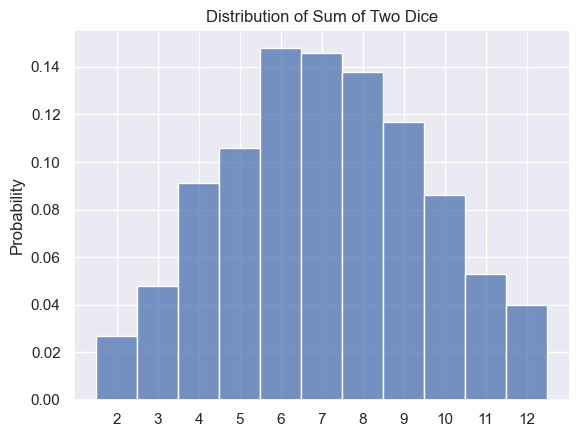

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme()
sns.histplot(dices_experiment, discrete=True,  stat="probability")
# Optional: Add labels to make it clear
plt.xticks(range(2, 13))  # Force x-axis to show every integer from 2 to 12
plt.title("Distribution of Sum of Two Dice")
plt.show()
